In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
import os
print(os.listdir("/content"))

['.config', 'monthly_sales.csv', 'online_retail', 'online+retail.zip', 'cleaned_ecommerce_sales.csv', 'sample_data']


In [36]:

import pandas as pd

df = pd.read_excel("/content/online_retail/Online Retail.xlsx")
print(df.shape)
df.head()


(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [34]:

import os

print(os.listdir("/content"))


['.config', 'monthly_sales.csv', 'online_retail', 'online+retail.zip', 'cleaned_ecommerce_sales.csv', 'sample_data']


In [39]:
import zipfile

with zipfile.ZipFile("/content/online+retail.zip", "r") as z: z.extractall("/content/online_retail")


In [32]:
df = pd.read_excel("/content/online_retail/Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df.shape

(541909, 8)

In [ ]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [30]:
df.isnull().sum().sort_values(ascending=False)

,0
CustomerID,135037
Description,1454
StockCode,0
InvoiceNo,0
InvoiceDate,0
Quantity,0
UnitPrice,0
Country,0
Sales,0
Month,0


In [31]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135037
Country,0
Sales,0
Month,0


In [ ]:
df.duplicated().sum()

np.int64(5268)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.shape

(536641, 8)

In [ ]:
(df["Quantity"] < 0).sum(),
(df["UnitPrice"] < 0).sum()

np.int64(2)

In [13]:
df["Sales"] = df["Quantity"] * df["UnitPrice"]
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12,20.34


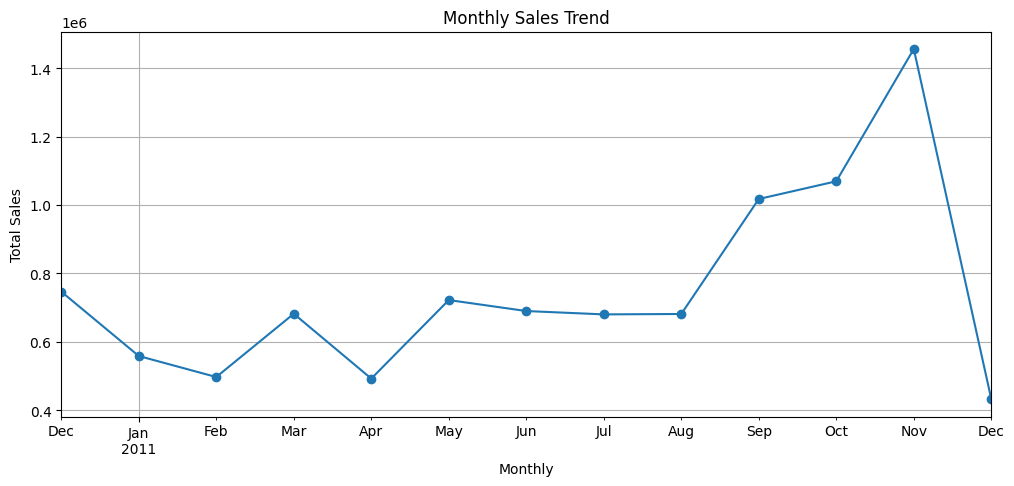

In [29]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Month"] = df["InvoiceDate"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Sales"].sum()

monthly_sales.plot(kind="line", figsize=(12,5), marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Monthly")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

In [11]:
import pandas as pd

df = pd.read_excel("/content/online_retail/Online Retail.xlsx")

In [10]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Shape: (541909, 8)

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [ ]:
import os

os.listdir("/content")

['.config', 'sample_data']

In [9]:
import zipfile
import os
with zipfile.ZipFile("/content/online+retail.zip", "r") as z: z.extractall("/content/online_retail")

os.listdir("/content/online_retail")

['Online Retail.xlsx']

In [7]:
import pandas as pd

df = pd.read_excel("/content/online_retail/Online Retail.xlsx")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/content/online_retail/Online Retail.xlsx")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
import os
os.listdir("/content")

['.config', 'sample_data']

In [5]:
import zipfile
import os

with zipfile.ZipFile("/content/online+retail.zip", "r") as z:
    z.extractall("/content/online_retail")

print(os.listdir("/content/online_retail"))

['Online Retail.xlsx']


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("/content/online_retail/Online Retail.xlsx")

df_raw = df.copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [15]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

Missing values:


,0
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0



Duplicate rows: 5268


In [16]:
df = df_raw.copy()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

df = df.drop_duplicates()

df = df.dropna(
    subset=["InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice"]
)

# Keep positive sales transactions for this analysis
sales_df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales_df["Sales"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Cleaned rows:", len(sales_df))
print("Total positive sales:", round(sales_df["Sales"].sum(), 2))
display(sales_df.head())

Cleaned rows: 524878
Total positive sales: 10642110.8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [17]:
print("Missing values in sales data:")
display(sales_df.isnull().sum())

print("Duplicate rows:", sales_df.duplicated().sum())
print("Final shape:", sales_df.shape)

Missing values in sales data:


,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,132186
Country,0
Sales,0


Duplicate rows: 0
Final shape: (524878, 9)


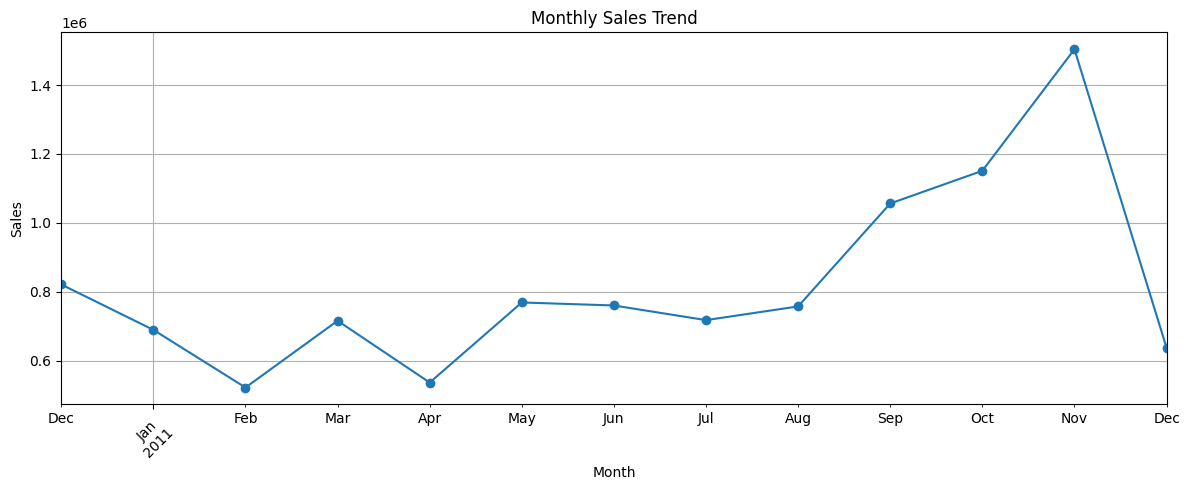

In [18]:
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M")

monthly_sales = sales_df.groupby("Month")["Sales"].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

,Sales
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


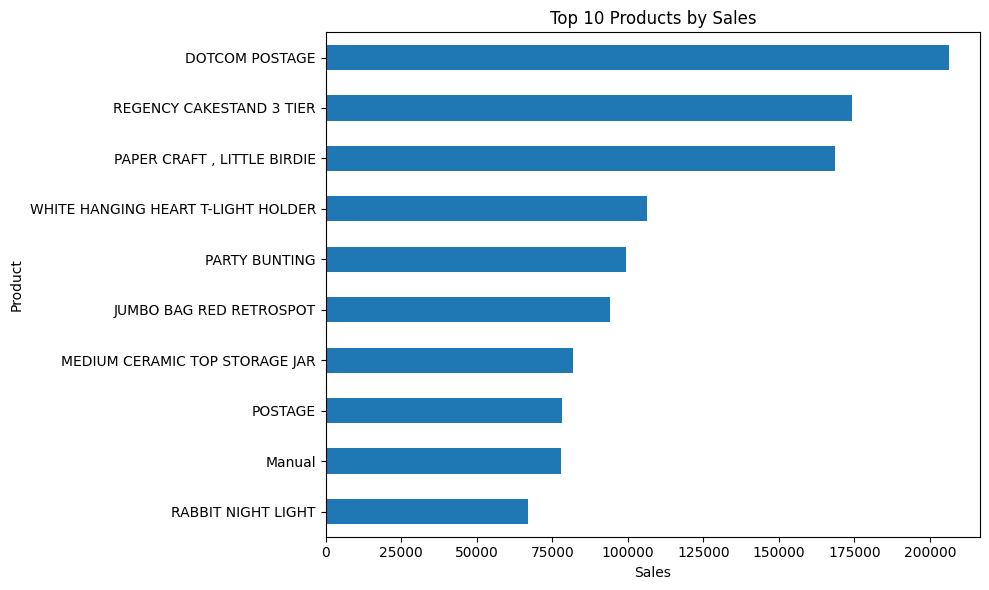

In [19]:
top_products = (
    sales_df.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

,Sales
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


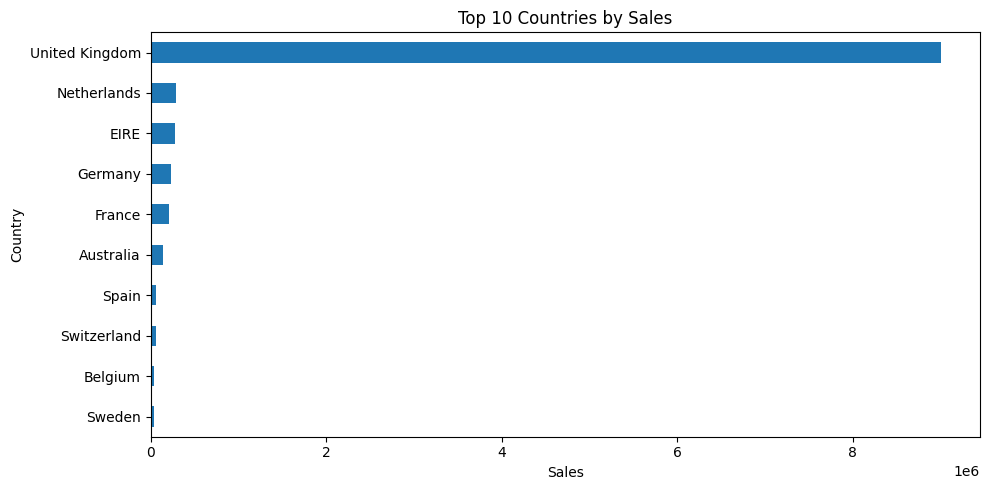

In [20]:
country_sales = (
    sales_df.groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_sales)

plt.figure(figsize=(10, 5))
country_sales.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Sales")
plt.xlabel("Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [21]:
customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

customer_sales = (
    customer_df.groupby("CustomerID")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Unique customers:", customer_df["CustomerID"].nunique())
print("\nTop 10 customers by sales:")
display(customer_sales.head(10))

Unique customers: 4338

Top 10 customers by sales:


,Sales
CustomerID,
14646.0,280206.02
18102.0,259657.30
17450.0,194390.79
16446.0,168472.50
14911.0,143711.17
12415.0,124914.53
14156.0,117210.08
17511.0,91062.38
16029.0,80850.84


,Sales
DayOfWeek,
Monday,1775782.071
Tuesday,2175700.511
Wednesday,1847074.380
Thursday,2199292.570
Friday,1837470.491
Saturday,NaN
Sunday,806790.781


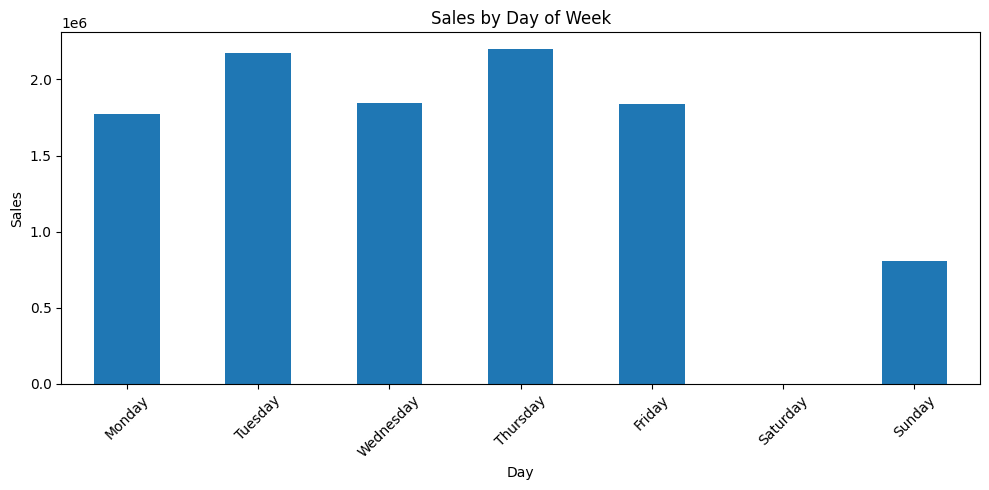

In [22]:
sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_sales = (
    sales_df.groupby("DayOfWeek")["Sales"]
    .sum()
    .reindex(day_order)
)

display(daily_sales)

plt.figure(figsize=(10, 5))
daily_sales.plot(kind="bar")
plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Actual Sales,Predicted Sales
InvoiceDate,,
2011-09,1056435.192,757841.38
2011-10,1151263.730,757841.38
2011-11,1503866.780,757841.38


Baseline MAE: 479347.19


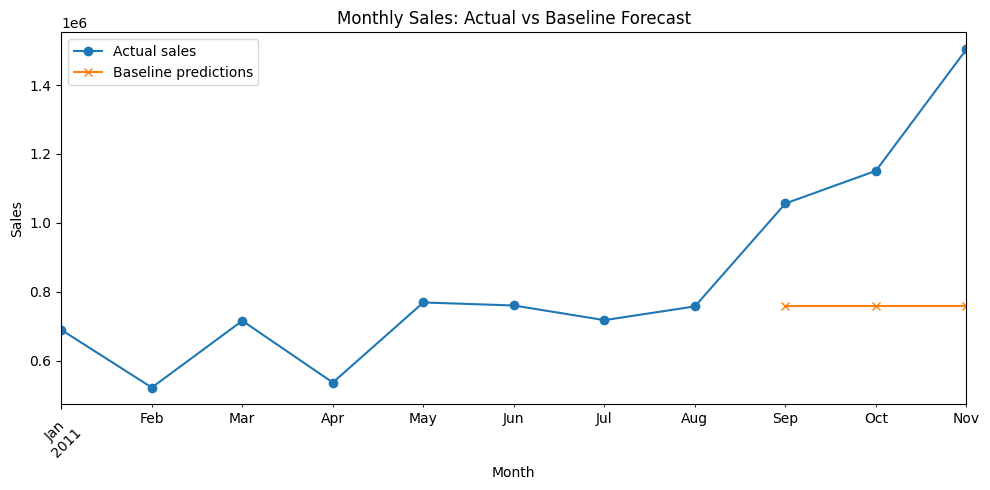

In [23]:
monthly = (
    sales_df.groupby(sales_df["InvoiceDate"].dt.to_period("M"))["Sales"]
    .sum()
    .sort_index()
)

# Remove incomplete first/last calendar months
monthly = monthly.iloc[1:-1]

if len(monthly) >= 6:
    train = monthly.iloc[:-3]
    test = monthly.iloc[-3:]

    # Simple baseline: predict each test month using last training month's sales
    predictions = pd.Series(
        [train.iloc[-1]] * len(test),
        index=test.index
    )

    results = pd.DataFrame({
        "Actual Sales": test,
        "Predicted Sales": predictions
    })

    display(results)

    mae = (results["Actual Sales"] - results["Predicted Sales"]).abs().mean()
    print("Baseline MAE:", round(mae, 2))

    plt.figure(figsize=(10, 5))
    monthly.plot(label="Actual sales", marker="o")
    predictions.plot(label="Baseline predictions", marker="x")
    plt.title("Monthly Sales: Actual vs Baseline Forecast")
    plt.xlabel("Month")
    plt.ylabel("Sales")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Not enough monthly data to evaluate this forecast.")

In [24]:
print("========== PROJECT SUMMARY ==========")
print("Total transactions:", sales_df["InvoiceNo"].nunique())
print("Unique products:", sales_df["StockCode"].nunique())
print("Unique countries:", sales_df["Country"].nunique())
print("Total positive sales:", round(sales_df["Sales"].sum(), 2))

print("\nTop-selling product:")
print(top_products.index[0])

print("\nTop country by sales:")
print(country_sales.index[0])

print("\nTop customer by sales:")
if not customer_sales.empty:
    print(customer_sales.index[0])
else:
    print("Customer IDs unavailable")

========== PROJECT SUMMARY ==========
Total transactions: 19960
Unique products: 3922
Unique countries: 38
Total positive sales: 10642110.8

Top-selling product:
DOTCOM POSTAGE

Top country by sales:
United Kingdom

Top customer by sales:
14646.0


In [25]:
sales_df.to_csv("/content/cleaned_ecommerce_sales.csv", index=False)
monthly_sales.to_csv("/content/monthly_sales.csv")

print("Project outputs saved successfully!")

Project outputs saved successfully!


In [26]:

from google.colab import files
files.download("cleaned_ecommerce_sales.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from google.colab import files

files.download("monthly_sales.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:

df["Sales"] = df["Quantity"] * df["UnitPrice"]

print(df[["Quantity", "UnitPrice", "Sales"]].head())


   Quantity  UnitPrice  Sales
0         6       2.55  15.30
1         6       3.39  20.34
2         8       2.75  22.00
3         6       3.39  20.34
4         6       3.39  20.34
